# 04 · Entrenamiento de los modelos base

Con el set de features interpretable ya definido (notebook 03), se entrenan
las cuatro familias de modelos sobre el mismo split de entrenamiento/prueba
usado en la selección de features. El conjunto de prueba se usa aquí **por
primera y única vez** para reportar el rendimiento — ninguna decisión de
diseño se tomó mirándolo.
Los modelos comparados son Ridge, Random Forest, XGBoost y LightGBM. Sus fundamentos se describen en Hoerl y Kennard (1970), Breiman (2001), Chen y Guestrin (2016) y Ke et al. (2017), respectivamente.

Configuración global cargada
Semilla: 1
RESUMEN DE LOS CONJUNTOS DE DATOS

Entrenamiento (AqSolDB, depurado)
  Moléculas: 6,592
  logS: [-12.06, 1.97]  media=-2.929  sd=2.359

Validación interna (AqSolDB, SD=0)
  Moléculas: 1,316
  logS: [-13.17, 2.14]  media=-2.975  sd=2.411

Validación externa1 (Delaney/ESOL)
  Moléculas: 1,128
  logS: [-11.60, 1.58]  media=-3.050  sd=2.096

Validación externa2 (Tight_SC-2)
  Moléculas: 100
  logS: [-6.79, -1.18]  media=-4.027  sd=1.272

Validación externa3 (Loose_SC-2)
  Moléculas: 32
  logS: [-10.40, -1.24]  media=-5.241  sd=2.176


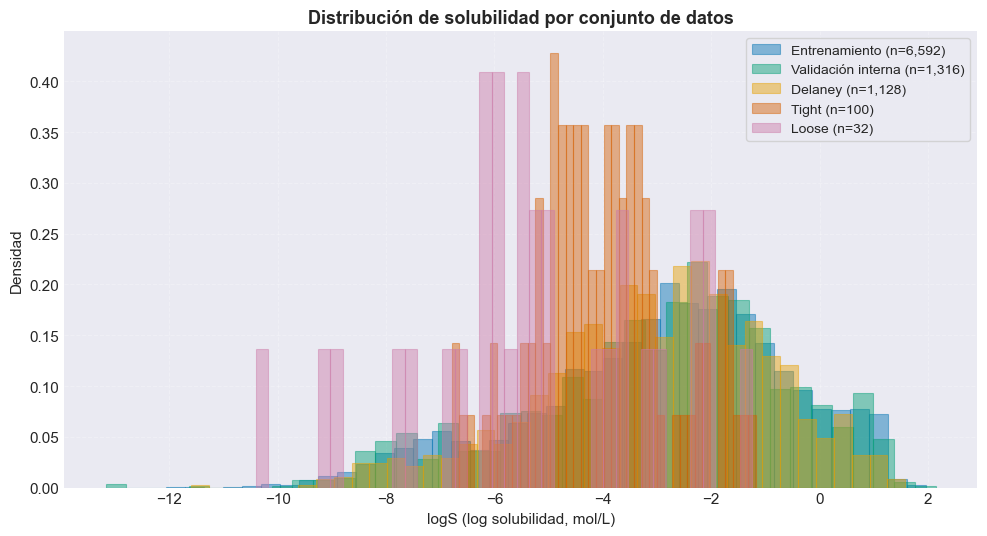

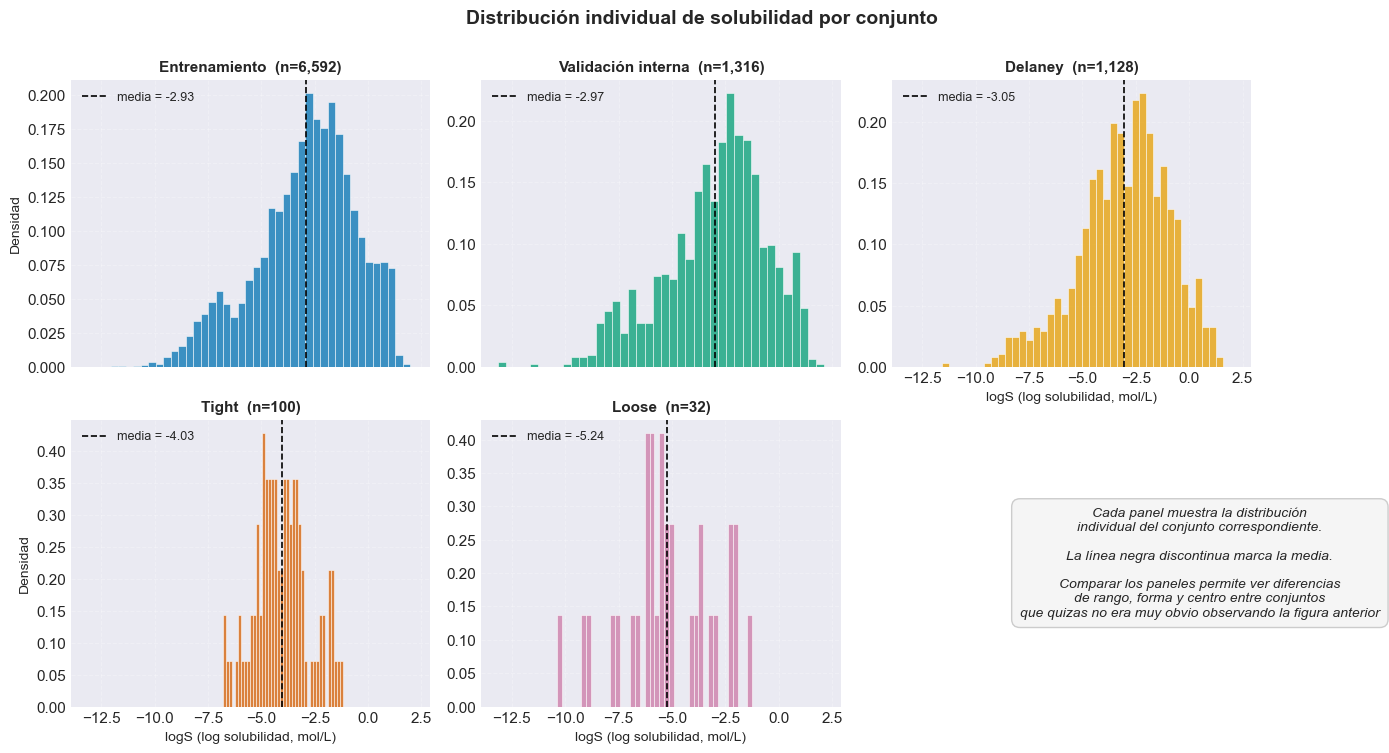

Features usadas: 13
Entrenamiento: 5273 moléculas | Prueba: 1319 moléculas


In [7]:
%run 02_configuracion_y_datos.ipynb

datos_features = joblib.load('../resultados/features/seleccion_features.pkl')
features_finales = datos_features['features_finales']

excluir = ['ID', 'Name', 'InChI', 'InChIKey', 'SMILES',
           'Solubility', 'SD', 'Occurrences', 'Group', 'Ipc']
columnas_features = [col for col in df_entrenamiento.columns if col not in excluir]

x = df_entrenamiento[columnas_features]
y = df_entrenamiento['Solubility']

# Mismo split que en el notebook 03 (misma semilla, mismo dataframe de origen)
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=RANDOM_STATE
)

# Restringir a las features finales
x_train = x_train[features_finales]
x_test = x_test[features_finales]

print(f"Features usadas: {len(features_finales)}")
print(f"Entrenamiento: {x_train.shape[0]} moléculas | Prueba: {x_test.shape[0]} moléculas")

In [8]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

modelos_base = {
    'Ridge': {'modelo': Ridge(alpha=1.0, random_state=RANDOM_STATE), 'escalar': True},
    'Random Forest': {'modelo': RandomForestRegressor(
        n_estimators=200, max_depth=12, min_samples_split=8, min_samples_leaf=4,
        max_features='sqrt', random_state=RANDOM_STATE, n_jobs=-1), 'escalar': False},
    'XGBoost': {'modelo': XGBRegressor(
        n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8,
        colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1, verbosity=0), 'escalar': False},
    'LightGBM': {'modelo': LGBMRegressor(
        n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8,
        feature_fraction=0.8, random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1), 'escalar': False},
}


def entrenar_y_evaluar(nombre, modelo, x_train, y_train, x_test, y_test, escalar):
    """Entrena un modelo y lo evalua UNA VEZ en x_test. Si requiere escalado,
    guarda el scaler para reutilizarlo en validacion externa (nunca reajustar
    un scaler nuevo sobre datos que el modelo no vio en entrenamiento)."""
    if escalar:
        scaler = StandardScaler().fit(x_train)
        x_train_proc, x_test_proc = scaler.transform(x_train), scaler.transform(x_test)
        os.makedirs('../resultados/modelos', exist_ok=True)
        joblib.dump(scaler, f'../resultados/modelos/scaler_{nombre.lower().replace(" ", "_")}.pkl')
    else:
        x_train_proc, x_test_proc = x_train, x_test

    inicio = time.time()
    modelo.fit(x_train_proc, y_train)
    tiempo_entrenamiento = time.time() - inicio

    inicio = time.time()
    y_pred_train = modelo.predict(x_train_proc)
    y_pred_test = modelo.predict(x_test_proc)
    tiempo_prediccion = time.time() - inicio

    return {
        'nombre': nombre, 'modelo': modelo,
        'r2_train': r2_score(y_train, y_pred_train),
        'r2_test': r2_score(y_test, y_pred_test),
        'mae_test': mean_absolute_error(y_test, y_pred_test),
        'rmse_test': np.sqrt(mean_squared_error(y_test, y_pred_test)),
        'tiempo_entrenamiento_s': tiempo_entrenamiento,
        'tiempo_prediccion_s': tiempo_prediccion,
        'y_pred_test': y_pred_test,
    }


resultados = []
for nombre, config in modelos_base.items():
    print(f"▶ Entrenando {nombre}...")
    resultado = entrenar_y_evaluar(nombre, config['modelo'], x_train, y_train, x_test, y_test, config['escalar'])
    resultados.append(resultado)
    print(f"  R² test = {resultado['r2_test']:.4f}  |  sobreajuste = {resultado['r2_train'] - resultado['r2_test']:.4f}")

df_resultados = pd.DataFrame(resultados)

▶ Entrenando Ridge...
  R² test = 0.6617  |  sobreajuste = -0.0033
▶ Entrenando Random Forest...
  R² test = 0.8054  |  sobreajuste = 0.0935
▶ Entrenando XGBoost...
  R² test = 0.8228  |  sobreajuste = 0.1425
▶ Entrenando LightGBM...
  R² test = 0.8199  |  sobreajuste = 0.1083


## Tabla comparativa de los 4 modelos base

In [9]:
tabla = df_resultados[['nombre', 'r2_train', 'r2_test', 'mae_test', 'rmse_test',
                        'tiempo_entrenamiento_s', 'tiempo_prediccion_s']].copy()
tabla['sobreajuste'] = tabla['r2_train'] - tabla['r2_test']

os.makedirs('../resultados/tablas', exist_ok=True)
tabla.to_csv('../resultados/tablas/comparacion_modelos_base.csv', index=False)
print(tabla.round(4).to_string(index=False))

       nombre  r2_train  r2_test  mae_test  rmse_test  tiempo_entrenamiento_s  tiempo_prediccion_s  sobreajuste
        Ridge    0.6584   0.6617    1.0134     1.3430                  0.0378               0.0000      -0.0033
Random Forest    0.8990   0.8054    0.7431     1.0186                  2.8181               0.3350       0.0935
      XGBoost    0.9653   0.8228    0.6918     0.9720                  1.0997               0.0469       0.1425
     LightGBM    0.9281   0.8199    0.7033     0.9801                  0.4210               0.0781       0.1083


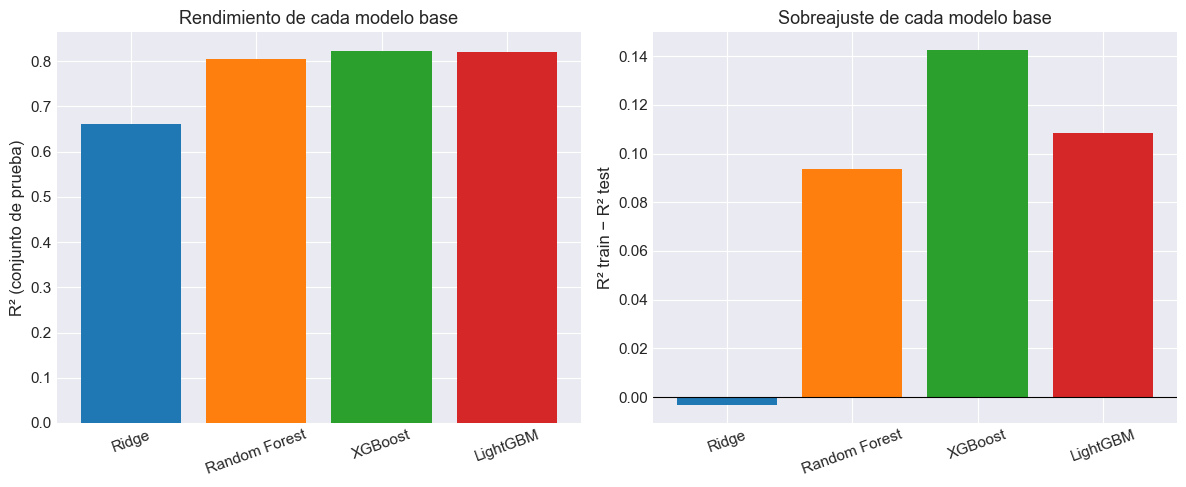

In [10]:
# Figura: R2 de prueba y sobreajuste
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colores = [COLORES.get(n, '#999999') for n in tabla['nombre']]
axes[0].bar(tabla['nombre'], tabla['r2_test'], color=colores)
axes[0].set_ylabel('R² (conjunto de prueba)')
axes[0].set_title('Rendimiento de cada modelo base')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(tabla['nombre'], tabla['sobreajuste'], color=colores)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_ylabel('R² train − R² test')
axes[1].set_title('Sobreajuste de cada modelo base')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('../resultados/graficos/05_comparacion_modelos_base.png', dpi=150)
plt.show()

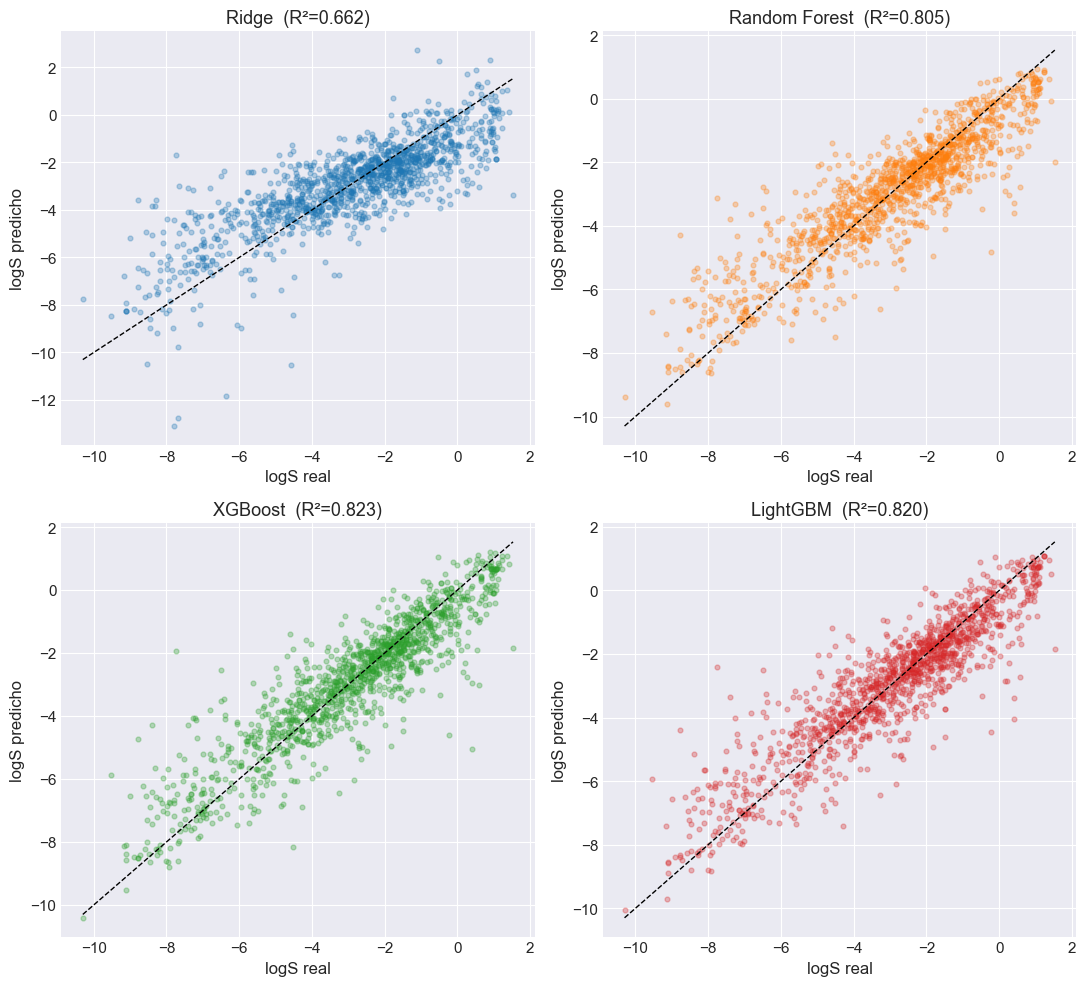

In [11]:
# Figura: prediccion vs valor real
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, resultado in zip(axes.flat, resultados):
    color = COLORES.get(resultado['nombre'], '#999999')
    ax.scatter(y_test, resultado['y_pred_test'], alpha=0.3, s=12, color=color)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, 'k--', linewidth=1)
    ax.set_xlabel('logS real')
    ax.set_ylabel('logS predicho')
    ax.set_title(f"{resultado['nombre']}  (R²={resultado['r2_test']:.3f})")

plt.tight_layout()
plt.savefig('../resultados/graficos/06_prediccion_vs_real_modelos_base.png', dpi=150)
plt.show()

In [12]:
# Guardar modelos entrenados y resultados
for r in resultados:
    nombre_archivo = f"../resultados/modelos/{r['nombre'].lower().replace(' ', '_')}_base.pkl"
    joblib.dump(r['modelo'], nombre_archivo)

joblib.dump(resultados, '../resultados/modelos_base_resultados.pkl')
print("Modelos y resultados guardados en ../resultados/modelos/")

Modelos y resultados guardados en ../resultados/modelos/
